In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
df = pd.read_csv(r"C:\Users\SHIVA\Downloads\retail_sales.csv")



In [18]:
df

,Date,Product,Category,Price,Quantity Sold,Total Sales
0,2025-01-02,Jeans,Clothing,1800.0,5.0,9000.0
1,2025-01-02,Sneakers,Clothing,2800.0,2.0,5600.0
2,2025-01-03,T-Shirt,Clothing,600.0,4.0,2400.0
3,2025-01-04,Cushion,Home,400.0,3.0,1200.0
4,2025-01-06,Snacks Pack,Groceries,120.0,6.0,720.0
...,...,...,...,...,...,...
495,2025-12-29,Coffee,Groceries,350.0,8.0,2800.0
496,2025-12-29,Olive Oil,Groceries,700.0,2.0,1400.0
497,2025-12-31,Snacks Pack,Groceries,120.0,2.0,240.0
498,2025-12-31,Jeans,Clothing,1800.0,2.0,3600.0


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           500 non-null    str    
 1   Product        500 non-null    str    
 2   Category       500 non-null    str    
 3   Price          495 non-null    float64
 4   Quantity Sold  495 non-null    float64
 5   Total Sales    495 non-null    float64
dtypes: float64(3), str(3)
memory usage: 36.3 KB


                                                 OBJECT ORIENTED PROGRAMMS

In [ ]:
class RetailAnalyzer:
    def __init__(self):
        self.df = None
        self.metrics = {}

    def load_data(self, file_path):
        self.df = pd.read_csv(r"C:\Users\SHIVA\Downloads\retail_sales.csv")
        print()

    def calculate_metrics(self):
        """Total sales, average sales, most popular product"""
        self.metrics["total_sales"] = self.df["Total Sales"].sum()
        self.metrics["average_sales"] = self.df["Total Sales"].mean()
        self.metrics["popular_product"] = self.df["Product"].value_counts().idxmax()

    def filter_data(self, condition):
        {"Category": "Electronics"}
        {"start_date": "2024-01-01", "end_date": "2024-03-31"}
        
        filtered = self.df.copy()

        if "Category" in condition:
            filtered = filtered[filtered["Category"] == condition["Category"]]

        if "start_date" in condition and "end_date" in condition:
            filtered["Date"] = pd.to_datetime(filtered["Date"])
            filtered = filtered[
                (filtered["Date"] >= condition["start_date"]) &
                (filtered["Date"] <= condition["end_date"])
            ]

        return filtered

    def display_summary(self):
        print("===== Retail Sales Summary =====")
        print(f"Total Sales     : {self.metrics['total_sales']}")
        print(f"Average Sales   : {self.metrics['average_sales']:.2f}")
        print(f"Popular Product : {self.metrics['popular_product']}")
        print("================================")


In [47]:
analyzer = RetailAnalyzer()
analyzer.load_data(r"C:\Users\SHIVA\Downloads\retail_sales.csv")

In [41]:
analyzer.df.head()

,Date,Product,Category,Price,Quantity Sold,Total Sales
0,2025-01-02,Jeans,Clothing,1800.0,5.0,9000.0
1,2025-01-02,Sneakers,Clothing,2800.0,2.0,5600.0
2,2025-01-03,T-Shirt,Clothing,600.0,4.0,2400.0
3,2025-01-04,Cushion,Home,400.0,3.0,1200.0
4,2025-01-06,Snacks Pack,Groceries,120.0,6.0,720.0


In [50]:
Electronics =analyzer.filter_data({"Category": "Electronics"})
print(Electronics.head())

          Date     Product     Category    Price  Quantity Sold  Total Sales
6   2025-01-08  Smartwatch  Electronics   5000.0            3.0      15000.0
16  2025-01-19  Smartwatch  Electronics   5000.0            3.0      15000.0
23  2025-01-25  Headphones  Electronics   2000.0            NaN       4000.0
27  2025-01-29  Smartphone  Electronics  15000.0            2.0      30000.0
29  2025-02-02  Smartphone  Electronics  15000.0            2.0      30000.0


In [51]:
analyzer.calculate_metrics()
print(analyzer.metrics)

{'total_sales': np.float64(5373980.0), 'average_sales': np.float64(10856.525252525253), 'popular_product': 'Rice 5kg'}


In [53]:
analyzer.display_summary()

===== Retail Sales Summary =====
Total Sales     : 5373980.0
Average Sales   : 10856.53
Popular Product : Rice 5kg


                                                    DATA MANIPULATION

NumPy

In [56]:
analyzer.df.isnull().sum()

Date             0
Product          0
Category         0
Price            5
Quantity Sold    5
Total Sales      5
dtype: int64

In [58]:
df =analyzer.df
df["Date"] = pd.to_datetime(df["Date"])

Sales percentage

In [68]:
cat_sales = df.groupby("Category")["Total Sales"].sum()
cat_Percentage= np.round(cat_sales / cat_sales.sum() *100,2)
print(cat_Percentage)


Category
Clothing       18.39
Electronics    66.30
Groceries       5.19
Home           10.12
Name: Total Sales, dtype: float64


Growth Rate

In [71]:
df["Month"] = df["Date"].dt.to_period("M")
monthly_sales = df.groupby("Month")["Total Sales"].sum()

growth_rate = np.round(monthly_sales.pct_change() * 100, 2)
print(growth_rate)

Month
2025-01       NaN
2025-02    100.54
2025-03     98.45
2025-04    -51.99
2025-05     46.04
2025-06    -45.06
2025-07    111.35
2025-08    -11.35
2025-09    -47.73
2025-10     62.14
2025-11     45.81
2025-12    -47.65
Freq: M, Name: Total Sales, dtype: float64


Pandas

In [72]:
print(df.isnull().sum())

Date             0
Product          0
Category         0
Price            5
Quantity Sold    5
Total Sales      5
Month            0
dtype: int64


In [76]:
df["Price"] = df["Price"].fillna(df["Price"].mean())
df["Quantity Sold"] = df["Quantity Sold"].fillna(df["Quantity Sold"].median())

# Total Sales ko dobara calculate karne ke liye (Price x Quantity)
df["Total Sales"] = df["Price"] * df["Quantity Sold"]


In [77]:
print(df.isnull().sum())   

Date             0
Product          0
Category         0
Price            0
Quantity Sold    0
Total Sales      0
Month            0
dtype: int64


In [79]:
data= df.groupby("Category").agg(
    total_sales=("Total Sales", "sum"),
    avg_sales=("Total Sales", "mean"),
    total_quantity=("Quantity Sold", "sum")
)
print(data)

              total_sales     avg_sales  total_quantity
Category                                               
Clothing     1.021000e+06   8233.870968           498.0
Electronics  3.598685e+06  28789.481051           282.0
Groceries    3.781462e+05   2908.816783           781.0
Home         5.904905e+05   4880.086986           523.0


In [80]:
df

,Date,Product,Category,Price,Quantity Sold,Total Sales,Month
0,2025-01-02,Jeans,Clothing,1800.0,5.0,9000.0,2025-01
1,2025-01-02,Sneakers,Clothing,2800.0,2.0,5600.0,2025-01
2,2025-01-03,T-Shirt,Clothing,600.0,4.0,2400.0,2025-01
3,2025-01-04,Cushion,Home,400.0,3.0,1200.0,2025-01
4,2025-01-06,Snacks Pack,Groceries,120.0,6.0,720.0,2025-01
...,...,...,...,...,...,...,...
495,2025-12-29,Coffee,Groceries,350.0,8.0,2800.0,2025-12
496,2025-12-29,Olive Oil,Groceries,700.0,2.0,1400.0,2025-12
497,2025-12-31,Snacks Pack,Groceries,120.0,2.0,240.0,2025-12
498,2025-12-31,Jeans,Clothing,1800.0,2.0,3600.0,2025-12


                                                        Data Visualization

Bar Chat

In [81]:
sns.set_theme(style="whitegrid")
df= analyzer.df
df["Date"] =pd.to_datetime(df["Date"])

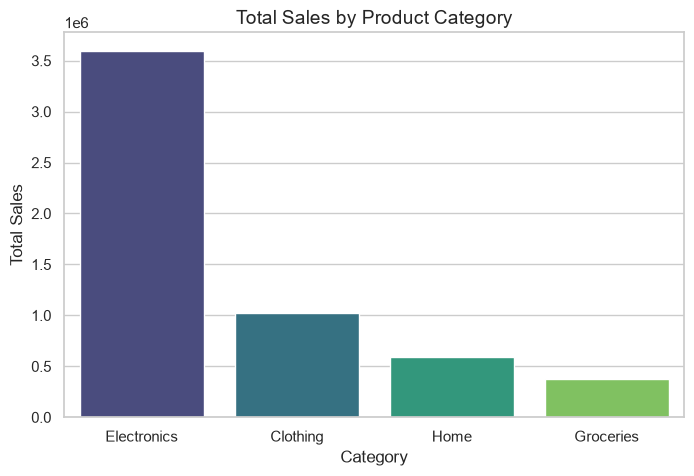

In [84]:
by_category = df.groupby("Category")["Total Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=by_category.index, y=by_category.values, hue=by_category.index, palette="viridis", legend=False)
plt.title("Total Sales by Product Category", fontsize=14)
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.show()

Line Graph

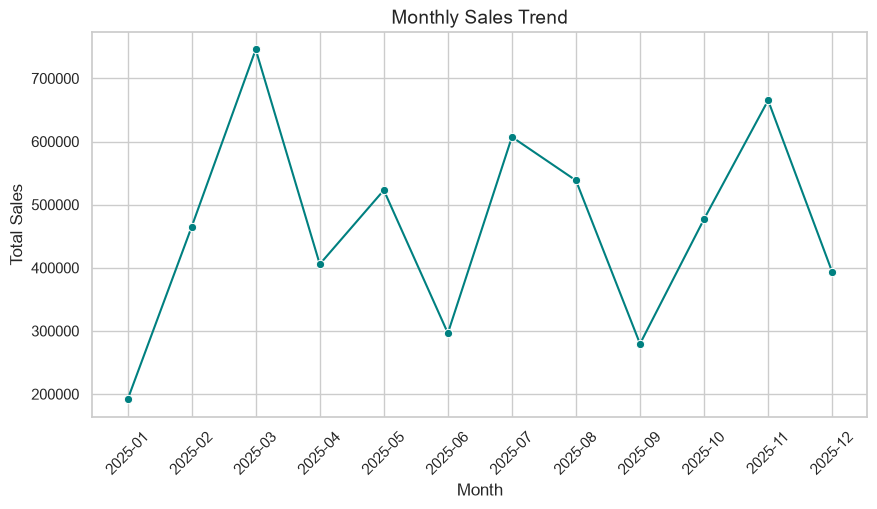

In [86]:
monthly_sales = df.groupby(df["Date"].dt.to_period("M"))["Total Sales"].sum()
monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(10, 5))
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker="o", color="teal")
plt.title("Monthly Sales Trend", fontsize=14)
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.ticklabel_format(style="plain", axis="y")
plt.show()

Heatmap

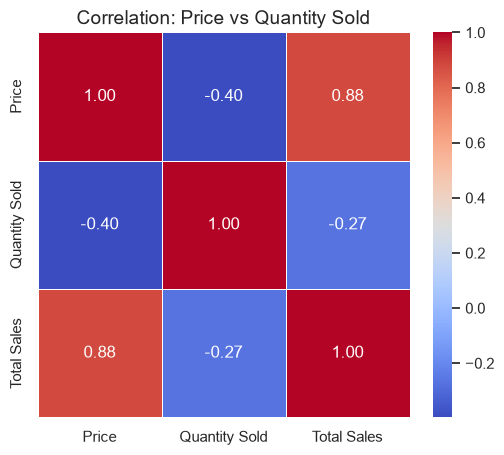

In [87]:
corr = df[["Price", "Quantity Sold", "Total Sales"]].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation: Price vs Quantity Sold", fontsize=14)
plt.show()